In [4]:
import pandas as pd
import numpy as np
import pylab as plt

import pypsa

# Import the public function from the package you completed
from energy_model import model_run

In [5]:
# Default parameters

# input database folder
db_dir = 'input_databases//default'

# model years
years = [2020,2030,2040,2050]

# intra-year temporal resolution
t_res = 15 # hours

# discount rates
rt = 0.07 # technical discount rate
rs = 0.01 # social discount rate

# passenger cars conversion factor
passenger_cars_cf = 40*0.1  # km/h


In [6]:
# Handy plotting functions. 
# Note that these are good to quickly diagnose your runs, 
# but for your final presentation and paper you will need
# nicer-looking plots, following the data-visualization 
# guidelines we discussed in class!

def plot_main_ebs(scen):
    fig, ax = plt.subplots(1,5)
    fig.set_size_inches(20,4)

    for n,c in enumerate(['Residential electricity',
            'Residential heat',
            'Transportation',
            'Industrial machinery',
            'Industrial HTP']): 
        df = scen.statistics.energy_balance(bus_carrier=c)
        df = df.set_index(df.index.get_level_values(1))
        df.T.plot(kind='bar',stacked='True', rot=0, colormap='tab20',ax=ax[n])
        if c=='Transportation':
            ax[n].set_ylabel('Mvkm')
        else:
            ax[n].set_ylabel('MWh')
        ax[n].set_title(c)

    fig.tight_layout()

def plot_elc_emi(scen):
    fig, ax = plt.subplots(1,5)
    fig.set_size_inches(20,4)

    for n,c in enumerate(['Electricity','CO2 atmosphere', 'CO2 storage']):
        df = scen.statistics.energy_balance(bus_carrier=c)
        df = df.set_index(df.index.get_level_values(1))
        df.T.plot(kind='bar',stacked='True', rot=0, colormap='tab20', ax=ax[n])

        if 'CO2' in c:
            ax[n].set_ylabel('tCO2')
        else:
            ax[n].set_ylabel('MWh')
        ax[n].set_title(c)
        ax[n].legend(bbox_to_anchor=(1,-0.5))

    # Let's add cumulative CO2
    for n,c in enumerate(['CO2 atmosphere', 'CO2 storage']):
        df = scen.statistics.energy_balance(bus_carrier=c).cumsum(axis=1)
        df = df.set_index(df.index.get_level_values(1))
        df.T.plot(kind='bar', stacked=True, colormap='tab20', ax=ax[n+3])
        ax[n+3].set_ylabel('tCO2')
        ax[n+3].set_title(f'Cumulative {c}')
        ax[n+3].legend(bbox_to_anchor=(1,-0.5))

    fig.tight_layout()


In [7]:
base = model_run(db_dir,years,t_res,passenger_cars_cf,rt,rs)
base.name = 'base'

KeyError: 'hydrogen_industry'

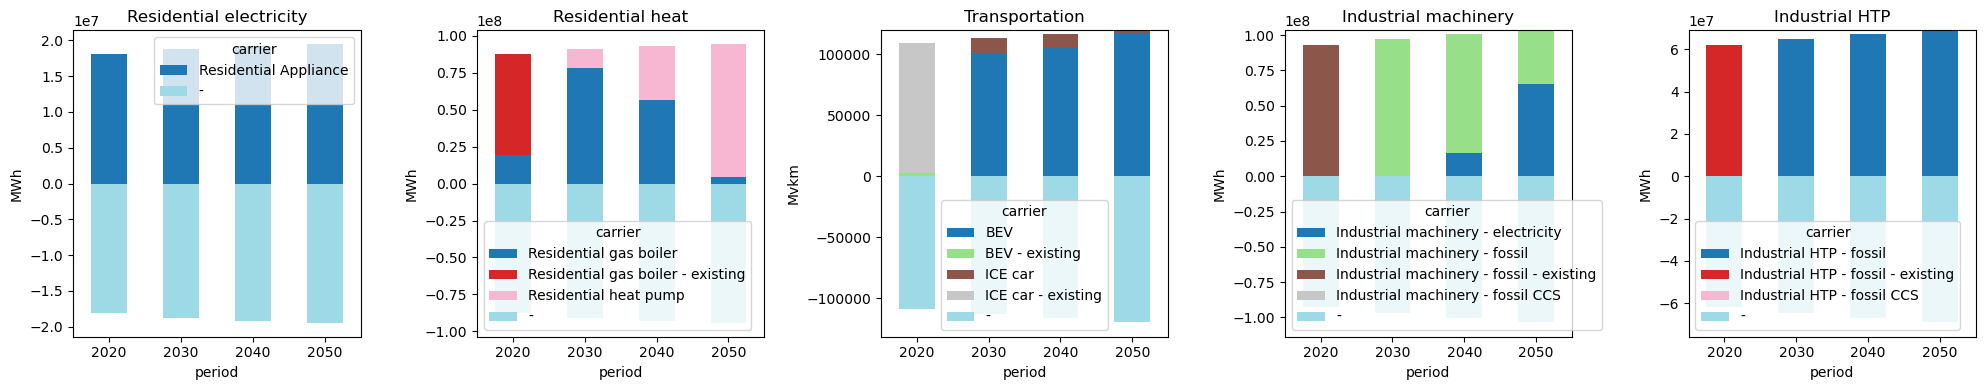

In [ ]:
# Let's have a quick look at the demand-side energy balances:
plot_main_ebs(base)

C:\Users\dallalongaf\AppData\Local\Temp\ipykernel_32448\992169818.py:48: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


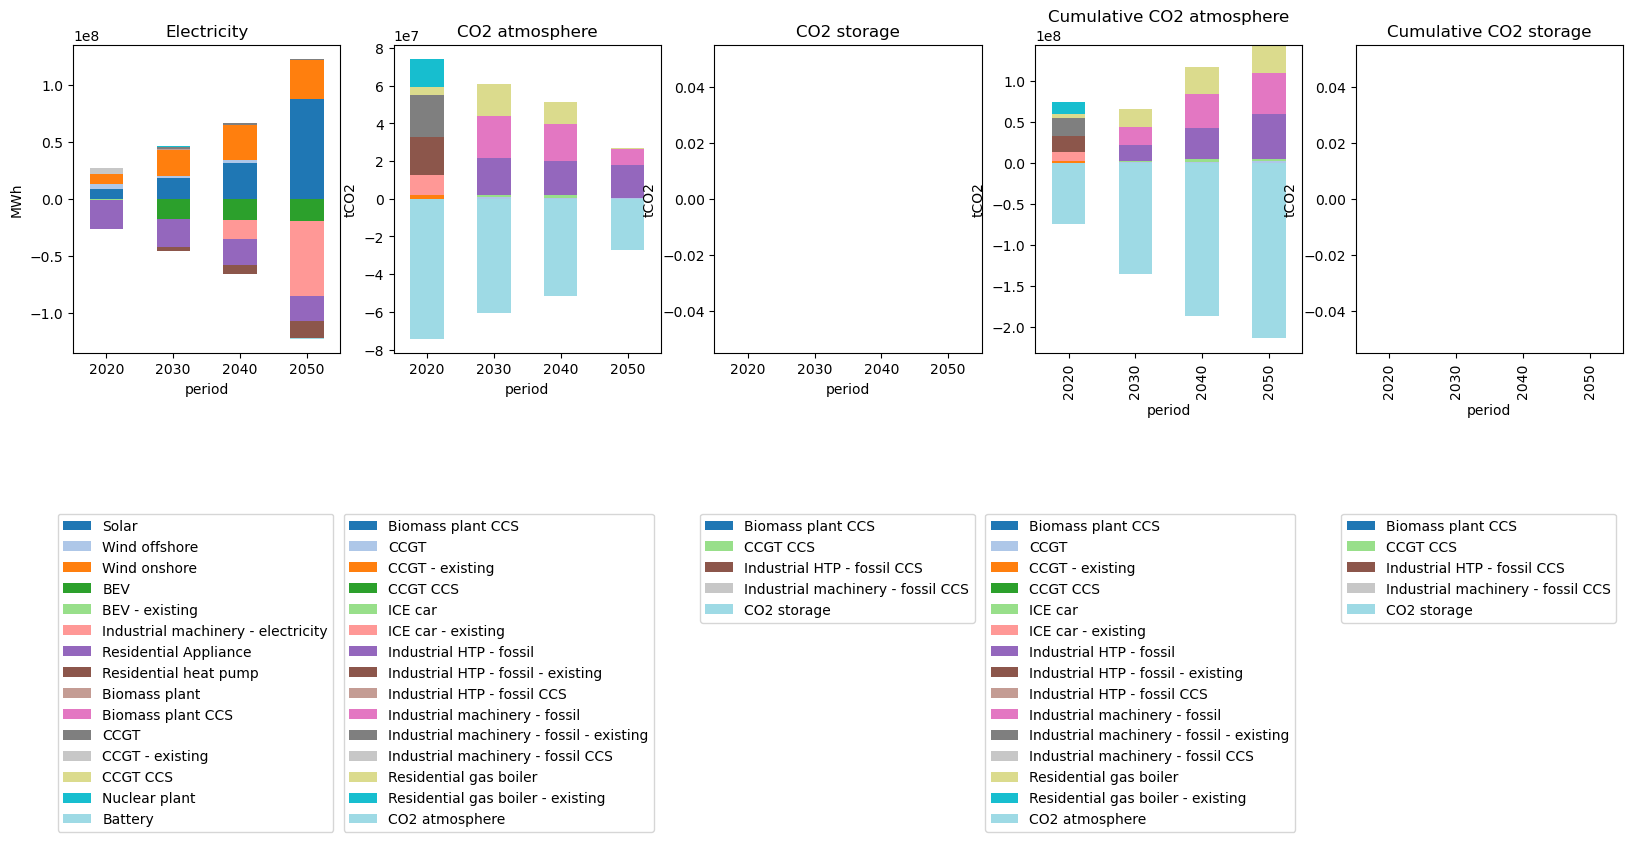

In [ ]:
# Let's also look at electricity supply and emissions
plot_elc_emi(base)

### My stuff ghere 

In [8]:
def plot_h2_eb(scen):
    fig, ax = plt.subplots(1, 1)
    fig.set_size_inches(8, 4)

    df = scen.statistics.energy_balance(bus_carrier='Hydrogen')
    df = df.set_index(df.index.get_level_values(1))
    df.T.plot(kind='bar', stacked=True, rot=0, colormap='tab20', ax=ax)
    ax.set_ylabel('MWh')
    ax.set_title('Hydrogen demand')
    ax.legend(bbox_to_anchor=(1, -0.5))
    fig.tight_layout()

In [10]:
# Scenario low: electrolysis limited to 20% of H2 demand in 2020, growing to 40% by 2050
scen_lo = model_run(db_dir, years, t_res, passenger_cars_cf, rt, rs,
                    electrolysis_fraction={2020: 0.0, 2030: 0.2, 2040: 0.3, 2050: 0.4})
scen_lo.name = 'low_green'

# Scenario mid: electrolysis grows to ~70% by 2050
scen_mid = model_run(db_dir, years, t_res, passenger_cars_cf, rt, rs,
                     electrolysis_fraction={2020: 0.0, 2030: 0.4, 2040: 0.6, 2050: 0.7})
scen_mid.name = 'mid_green'

# Scenario high: strong electrolysis rollout, nearly fully green by 2050
scen_hi = model_run(db_dir, years, t_res, passenger_cars_cf, rt, rs,
                    electrolysis_fraction={2020: 0.0, 2030: 0.6, 2040: 0.8, 2050: 0.95})
scen_hi.name = 'high_green'

TypeError: model_run() got an unexpected keyword argument 'electrolysis_fraction'